# CesiCDP · Static CVRPTW mathematical modeling
## Deliverable 1 — capacity, hard service-start windows and visual validation

The selected scope is one depot, at most K identical-capacity vehicles, mandatory unsplit customers, static travel, customer service durations, hard service-start windows, early waiting, depot opening/closing, and minimum total traveled distance under the bundled reference convention.

This notebook develops routing and temporal equations, then validates supplied Solomon and Gehring–Homberger reference routes. It does not implement an optimization algorithm or establish final experiment results.

## Notebook navigation / deliverable checklist

- [x] Context and problem scope
- [x] Formal data, notation, and assumptions
- [x] Decision variables and domains
- [x] Objective function and full ILP/MILP formulation
- [x] All feasibility constraints, including subtour elimination
- [x] NP-hardness proof (TSP reduction)
- [x] Illustrative model and constraint visualization
- [x] Synthetic, parameterized data demonstrations
- [x] Real CVRPTW instances and independent reference validation
- [x] Mathematical-model sizing and limitations
- [x] Bibliographic references
- [ ] Tutor review, feedback, and correction log (to be completed by the team)

**Storytelling principle:** each section asks a concrete question, introduces the matching model component, and visually demonstrates why it matters.

The temporal formulation and static CVRPTW reference demonstrations appear in Sections 4.5 and 10A. All reported reference costs remain external results.

## 0 · Execution, configuration and evidence

Install `numpy pandas matplotlib vrplib` (and `nbformat nbclient ipykernel` for automated execution). Run from the repository root, or set `ECOROUTE_PROJECT_ROOT`. Dataset root defaults to `data/benchmarks/vrptw/`; override with `ECOROUTE_DATA_ROOT`. The default modeling run executes synthetic checks and marks collection-dependent work **NOT RUN** when files are missing. Set `ECOROUTE_STRICT_DATA=1` to fail on any missing pair. Present but malformed data or incorrect reference costs always fail, in either mode.

Download separately with `python scripts/download_vrptw_benchmarks.py`. Run All never downloads or changes source data. Saved outputs record one execution, not evidence of a fresh rerun on the reader's machine. Live UTC time, package versions, source manifest and per-file/collection hashes appear below. The synthetic seed is `SYNTHETIC.seed`; reference checking uses no randomness.


In [1]:
from __future__ import annotations

# Standard library dependencies: portable file paths, immutable configurations,
# annotations, regex parsing, and integer arithmetic.
from collections import Counter
from dataclasses import dataclass
from pathlib import Path
import math
import re
import warnings

# Scientific Python libraries are used for data analysis and plotting ONLY.
# No optimization solver or metaheuristic package is imported.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from IPython.display import display

try:
    import vrplib  # Preferred, official parser used in the later project phases.
    VRPLIB_AVAILABLE = True
except ImportError:
    vrplib = None
    VRPLIB_AVAILABLE = False

# Sensible display settings affect chart readability, never model constraints.
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 105,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 20)

print("vrplib installed:", VRPLIB_AVAILABLE)
print("NumPy:", np.__version__, "· Matplotlib:", plt.matplotlib.__version__)

# Reproducible, configurable roots. No network acquisition during Run All.
import os, sys, json, platform, hashlib
from datetime import datetime, timezone
PROJECT_ROOT = Path(os.environ.get("ECOROUTE_PROJECT_ROOT", Path.cwd())).resolve()
if not (PROJECT_ROOT / "scripts" / "cvrptw_model.py").is_file():
    raise FileNotFoundError("Run from repository root or set ECOROUTE_PROJECT_ROOT")
sys.path.insert(0, str(PROJECT_ROOT))
DATA_ROOT = Path(os.environ.get("ECOROUTE_DATA_ROOT", PROJECT_ROOT / "data" / "benchmarks" / "vrptw")).resolve()
STRICT_DATA = os.environ.get("ECOROUTE_STRICT_DATA", "0") == "1"
print("Fresh execution UTC:", datetime.now(timezone.utc).isoformat())
print("Dataset root:", DATA_ROOT, "strict:", STRICT_DATA)


vrplib installed: True
NumPy: 2.0.2 · Matplotlib: 3.9.4
Fresh execution UTC: 2026-11-09T17:11:42.378105+00:00
Dataset root: /Users/denni/EcoRoute-CVRPTW/data/benchmarks/vrptw strict: True


## 1 · From a delivery network to a graph

Let $G=(V,A)$ be a directed graph, where:

- $V=\{0,1,\ldots,n\}$ contains depot $0$ and customers.
- $A=\{(i,j):i,j\in V,\;i\ne j\}$ contains inter-location arcs.
- $F=\{1,\ldots,K\}$ contains at most $K$ available vehicles with capacity $Q$.
- Customer $i$ has demand $q_i$, service duration $s_i$, and service-start window $[a_i,b_i]$.
- $d_{ij}$ is the static travel distance between nodes; coordinates may be used to derive it.

Every customer is served exactly once, each used route starts and ends at the depot, capacity and time windows hold, and early arrival may wait. The objective is total route distance.

Distances and travel durations are separate configurable static matrices (equal under the selected native benchmark convention). Vehicles may choose a departure anywhere within the **same depot window**; no truck-specific departure windows are introduced. Waiting, travel duration and utilization are reported metrics, not objective terms.


### 1.1 · The difference between a parameter and a hard-coded decision

The *formula* $\sum_{i\in C}q_i y_{ik}\le Qz_k$ never changes. Only the supplied instance values $q_i$, $Q$, and $K$ change. A small demonstration with chosen numbers is not a restriction on the general model.

**Editable synthetic-data configuration:** the following values are illustrative defaults only. Change them to visualize different sizes, capacities, fleet limits, customer layouts, and demand distributions. There is **no optimizer** in the generator.

In [2]:
@dataclass(frozen=True)
class SyntheticConfig:
    # Every attribute below belongs to the input configuration, not to the ILP.
    n_customers: int = 42
    max_vehicles: int = 8
    vehicle_capacity: float = 35.0
    min_demand: int = 1
    max_demand: int = 9
    coordinate_max: float = 100.0
    depot_xy: tuple[float, float] = (50.0, 50.0)
    layout: str = "uniform"  # Other supported layout: "clustered".
    seed: int = 2026
    distance_policy: str = "raw"  # "raw", "nearest_integer", or "ceil".

# Change only this cell to change the synthetic *instance* across its plots.
SYNTHETIC = SyntheticConfig()

# A separately configurable small teaching example for route feasibility:
# these are illustrative example inputs, not limits imposed by the model.
EXAMPLE_COORDS = np.array([
    [50, 50], [14, 70], [21, 42], [35, 16],
    [75, 76], [86, 45], [62, 20],
], dtype=float)
EXAMPLE_DEMANDS = np.array([0, 6, 5, 4, 7, 3, 2], dtype=float)
EXAMPLE_CAPACITY = 16.0
EXAMPLE_MAX_VEHICLES = 3
EXAMPLE_ROUTES = [[1, 2, 3], [4, 5, 6]]  # Hand-written, NOT computed.

### 1.2 · A reusable, validated instance container

The instance container checks **data consistency**, not optimality. A minimal fleet lower bound is $\lceil (\sum_i q_i)/Q\rceil$; the inequality $\sum_i q_i\le KQ$ is necessary but not sufficient for packing customers into $K$ trucks. Example: three customers with demand 6 each, two trucks of capacity 10: total demand 18 is below 20, but the customers cannot fit in two unsplittable routes.

For convenience in code, every instance is internally **reindexed so the depot is location 0**. A mapping is retained for source dataset identifiers.

In [3]:
@dataclass
class CVRPInstance:
    name: str
    demands: np.ndarray          # One demand per node; depot demand must be 0.
    capacity: float               # Shared capacity of all K vehicles.
    max_vehicles: int             # Fleet upper bound; can differ by instance.
    distances: np.ndarray         # Matrix [node, node], supplied or generated.
    coordinates: np.ndarray | None = None
    original_ids: np.ndarray | None = None
    source: str = "synthetic"
    distance_policy: str = "raw"

    @property
    def n_customers(self) -> int:
        return len(self.demands) - 1

    @property
    def nodes(self) -> np.ndarray:
        return np.arange(len(self.demands))

    def check_input(self) -> list[str]:
        """Return problems, instead of silently assuming the data are valid."""
        problems = []
        q = np.asarray(self.demands)
        if q.ndim != 1 or q.size < 2:
            return ["Demand must be a vector containing depot plus customers"]
        m = q.size
        D = np.asarray(self.distances)
        if m < 2:
            problems.append("At least one customer is required for this demonstration.")
        if not isinstance(self.max_vehicles, (int, np.integer)) or self.max_vehicles < 1:
            problems.append("Fleet size must be a positive integer.")
        if not np.isfinite(self.capacity) or self.capacity <= 0:
            problems.append("Vehicle capacity must be strictly positive.")
        if len(np.asarray(self.demands).shape) != 1:
            problems.append("Demand vector must be one-dimensional.")
        elif not np.all(np.isfinite(self.demands)) or np.any(self.demands < 0):
            problems.append("Demands must be finite and nonnegative.")
        if len(self.demands) and not np.isclose(self.demands[0], 0):
            problems.append("The depot must have zero delivery demand.")
        if D.shape != (m, m):
            problems.append(f"Cost matrix has shape {D.shape}, expected {(m,m)}.")
        elif not np.all(np.isfinite(D)) or np.any(D < 0):
            problems.append("Distances must be finite and nonnegative.")
        if self.coordinates is not None and np.asarray(self.coordinates).shape != (m, 2):
            problems.append("Coordinates must have shape (number_of_nodes, 2).")
        if self.original_ids is not None and np.asarray(self.original_ids).shape != (m,):
            problems.append("Original ID mapping length does not match the instance.")
        if not problems and np.any(self.demands[1:] > self.capacity):
            problems.append("At least one customer demand exceeds one truck's capacity.")
        return problems


def euclidean_cost_matrix(coords: np.ndarray, policy: str = "raw") -> np.ndarray:
    """Compute pairwise 2-D straight-line distances; no routing takes place.

    'nearest_integer' intentionally uses floor(d + 0.5), rather than np.round:
    np.round uses ties-to-even, whereas many benchmark conventions use
    nearest-integer rounding. Always verify the convention per instance set.
    """
    coords = np.asarray(coords, dtype=float)
    delta = coords[:, None, :] - coords[None, :, :]
    D = np.sqrt(np.sum(delta * delta, axis=2))
    if policy == "raw":
        pass
    elif policy == "nearest_integer":
        D = np.floor(D + 0.5)
    elif policy == "ceil":
        D = np.ceil(D)
    else:
        raise ValueError("distance policy must be raw, nearest_integer, or ceil")
    np.fill_diagonal(D, 0.0)
    return D


def generate_synthetic(cfg: SyntheticConfig) -> CVRPInstance:
    """Generate input only. Never creates, evaluates, or optimizes routes."""
    if cfg.n_customers < 1 or cfg.min_demand < 0 or cfg.min_demand > cfg.max_demand:
        raise ValueError("Invalid customer count or demand range")
    rng = np.random.default_rng(cfg.seed)
    n = cfg.n_customers
    if cfg.layout == "uniform":
        customer_coords = rng.uniform(0, cfg.coordinate_max, size=(n, 2))
    elif cfg.layout == "clustered":
        centers = rng.uniform(0.15, 0.85, size=(3, 2)) * cfg.coordinate_max
        owners = rng.integers(0, len(centers), size=n)
        customer_coords = centers[owners] + rng.normal(
            0, 0.075 * cfg.coordinate_max, size=(n, 2)
        )
        customer_coords = np.clip(customer_coords, 0, cfg.coordinate_max)
    else:
        raise ValueError("Unknown layout. Use uniform or clustered.")
    coords = np.vstack([np.array(cfg.depot_xy), customer_coords])
    demands = np.r_[0, rng.integers(cfg.min_demand, cfg.max_demand + 1, n)]
    instance = CVRPInstance(
        name=f"Synthetic ({cfg.layout}, n={n}, seed={cfg.seed})",
        demands=demands.astype(float),
        capacity=float(cfg.vehicle_capacity),
        max_vehicles=int(cfg.max_vehicles),
        distances=euclidean_cost_matrix(coords, cfg.distance_policy),
        coordinates=coords,
        original_ids=np.arange(n + 1),
        source="generated data",
        distance_policy=cfg.distance_policy,
    )
    return instance

synthetic = generate_synthetic(SYNTHETIC)
small = CVRPInstance(
    name="Handwritten teaching example",
    demands=EXAMPLE_DEMANDS.copy(),
    capacity=EXAMPLE_CAPACITY,
    max_vehicles=EXAMPLE_MAX_VEHICLES,
    distances=euclidean_cost_matrix(EXAMPLE_COORDS),
    coordinates=EXAMPLE_COORDS,
    original_ids=np.arange(len(EXAMPLE_DEMANDS)),
)
for inst in (synthetic, small):
    errors = inst.check_input()
    print(f"{inst.name}: n={inst.n_customers}, K={inst.max_vehicles}, "
          f"Q={inst.capacity}, demand={inst.demands[1:].sum():.0f}, "
          f"input_errors={errors}")

Synthetic (uniform, n=42, seed=2026): n=42, K=8, Q=35.0, demand=228, input_errors=[]
Handwritten teaching example: n=6, K=3, Q=16.0, demand=27, input_errors=[]


### 1.3 · Visual question: where are the customers, and how large are their demands?

The marker sizes represent demand, **not route assignments**. The depot marker is separate. This plot demonstrates why geographic location and payload both matter; spatially close customers might collectively exceed a truck's capacity.

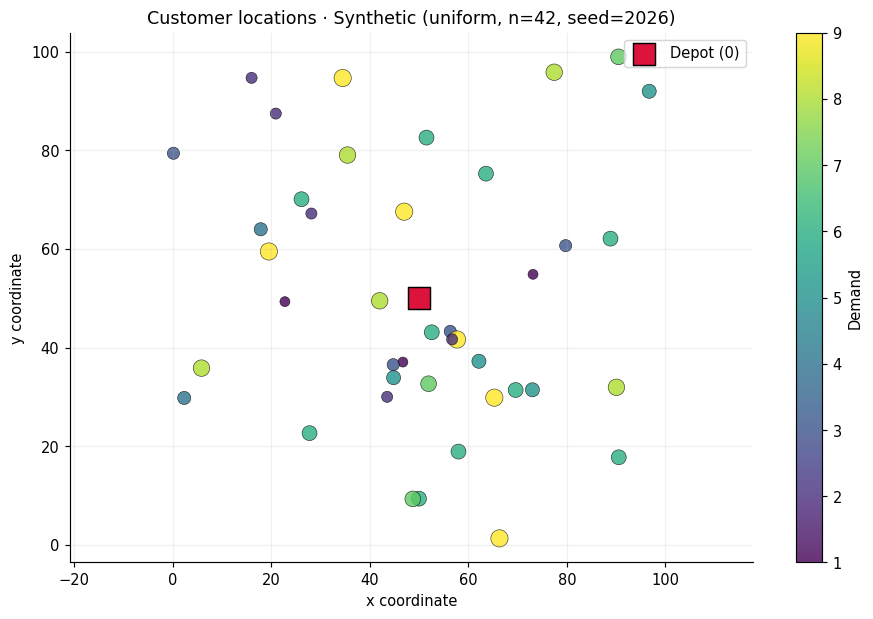

In [4]:
def plot_customer_map(instance: CVRPInstance, title: str | None = None, label: bool = False):
    """Show spatial inputs; optional coordinates are mandatory for this plot."""
    xy = instance.coordinates
    if xy is None:
        print("No coordinates provided; mapping skipped (distance matrix still usable).")
        return
    fig, ax = plt.subplots(figsize=(9, 6))
    q = instance.demands[1:]
    sizes = 35 + 15 * q / max(1, float(q.max())) * 7
    scatter = ax.scatter(xy[1:, 0], xy[1:, 1], s=sizes,
                         c=q, cmap="viridis", alpha=0.8, edgecolor="black", lw=0.4)
    ax.scatter([xy[0,0]], [xy[0,1]], marker="s", s=220, color="crimson",
               edgecolor="black", label="Depot (0)", zorder=5)
    if label and instance.n_customers <= 55:
        for i, (x, y) in enumerate(xy[1:], start=1):
            ax.annotate(str(i), (x, y), xytext=(3, 3), textcoords="offset points", fontsize=7)
    fig.colorbar(scatter, ax=ax, label="Demand")
    ax.set(xlabel="x coordinate", ylabel="y coordinate",
           title=title or f"Customer locations · {instance.name}")
    ax.set_aspect("equal", adjustable="datalim")
    ax.legend(loc="best")
    plt.tight_layout()
    plt.show()

plot_customer_map(synthetic)

### 1.4 · Demand profiles and elementary feasibility tests

Two easy necessary conditions for feasibility are:

$$\max_{i\in C}q_i\le Q,\qquad \sum_{i\in C}q_i\le KQ.$$

The capacity lower bound on **vehicles used** is:

$$L_K=\left\lceil\frac{\sum_{i\in C}q_i}{Q}\right\rceil.$$

**Caution:** these checks cannot prove full feasibility because unsplittable demands create a bin-packing restriction.

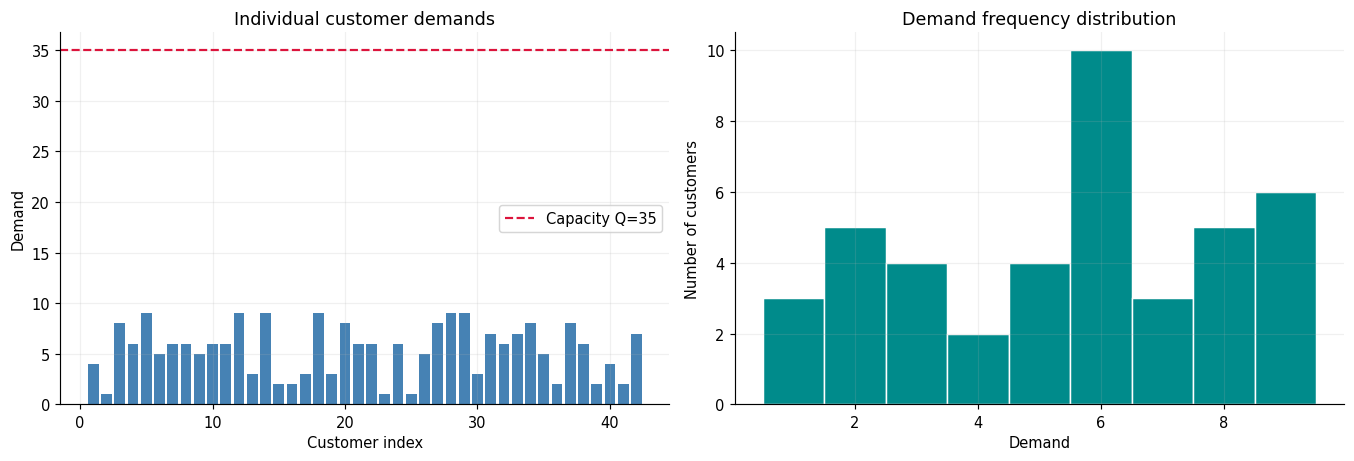

Total demand: 228 · available capacity KQ: 280
Necessary minimum trucks from aggregate capacity: 7
Individual demands within capacity: True
Aggregate demand within total fleet capacity: True


In [5]:
q = synthetic.demands[1:]
Q = synthetic.capacity
K = synthetic.max_vehicles
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.bar(np.arange(1, len(q)+1), q, color="steelblue")
ax1.axhline(Q, color="crimson", linestyle="--", label=f"Capacity Q={Q:g}")
ax1.set(xlabel="Customer index", ylabel="Demand", title="Individual customer demands")
ax1.legend()
ax2.hist(q, bins=np.arange(q.min()-0.5, q.max()+1.5, 1), color="darkcyan",
         edgecolor="white")
ax2.set(xlabel="Demand", ylabel="Number of customers", title="Demand frequency distribution")
plt.tight_layout(); plt.show()

lower_bound = math.ceil(float(q.sum()) / Q)
print(f"Total demand: {q.sum():g} · available capacity KQ: {K*Q:g}")
print(f"Necessary minimum trucks from aggregate capacity: {lower_bound}")
print("Individual demands within capacity:", bool((q <= Q).all()))
print("Aggregate demand within total fleet capacity:", bool(q.sum() <= K*Q))

### 1.5 · Why capacities and distribution are separate issues

A vehicle can have spare capacity while all customers remain individually unassignable under the remaining fleet allocation. This is why aggregate capacity alone does not prove feasibility.

Below, **six-unit customers with ten-unit trucks** illustrate how the aggregate capacity bound can be satisfied and the actual packing still impossible. This is a conceptual counterexample, **not** a solution attempt.

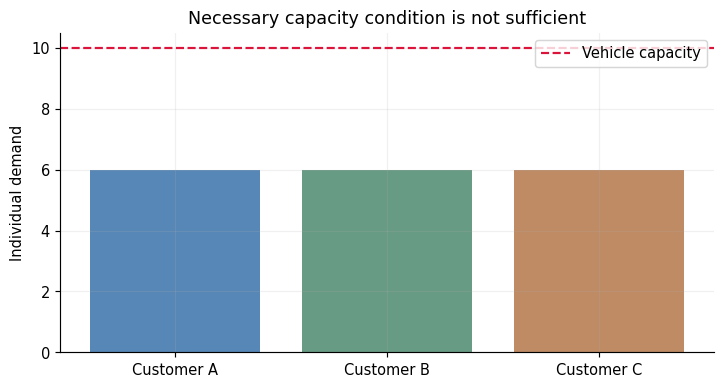

Sum of demand = 18 ≤ KQ = 20
But every pair has demand 12 > Q=10, so 3 vehicles would be required.


In [6]:
# These three figures are a logical counterexample, not a solver result.
packing_demands = np.array([6, 6, 6])
packing_Q, packing_K = 10, 2
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(["Customer A", "Customer B", "Customer C"], packing_demands,
       color=["#5787b7", "#689b84", "#be8b65"])
ax.axhline(packing_Q, color="crimson", linestyle="--", label="Vehicle capacity")
ax.set(ylabel="Individual demand", title="Necessary capacity condition is not sufficient")
ax.legend()
plt.tight_layout(); plt.show()
print("Sum of demand =", packing_demands.sum(), "≤ KQ =", packing_Q*packing_K)
print("But every pair has demand 12 > Q=10, so 3 vehicles would be required.")

## 2 · Decision variables: what exactly can be chosen?

For every truck $k\in F$ and arc $(i,j)\in A$:

$$x_{ijk}=\begin{cases}1,&\text{if truck }k\text{ travels directly from }i\text{ to }j,\\0,&\text{otherwise.}\end{cases}$$

For every customer $i\in C$ and truck $k\in F$:

$$y_{ik}=\begin{cases}1,&\text{if truck }k\text{ serves customer }i,\\0,&\text{otherwise.}\end{cases}$$

For each truck $k\in F$:

$$z_k=\begin{cases}1,&\text{if truck }k\text{ is used,}\\0,&\text{otherwise.}\end{cases}$$

For every customer $i\in C$ and truck $k\in F$, introduce an auxiliary **visit-order** variable $u_{ik}$.

$$u_{ik}=0\quad\text{if }y_{ik}=0;\qquad
1\le u_{ik}\le n\quad\text{if }y_{ik}=1.$$

The order variable is not an additional delivery decision: it exists to forbid customer-only cycles. It can be **continuous** because strict $+1$ sequencing constraints make it increase on every selected customer-to-customer arc; integer order variables are also allowed. With continuous $u$, the model is more precisely a **Mixed-Integer Linear Program (MILP)**, also commonly discussed under the broader PLNE/ILP heading.

**Why three kinds of binary variable?** $x$ expresses route *order*, $y$ identifies *assignment/load*, and $z$ distinguishes an *unused* truck from a real depot-to-depot route. These links will be enforced, not assumed.

### 2.1 · Visual interpretation of an arc decision

The diagram below illustrates one **hypothetical** truck route and the corresponding binary choices. It does **not** imply any optimization has happened.

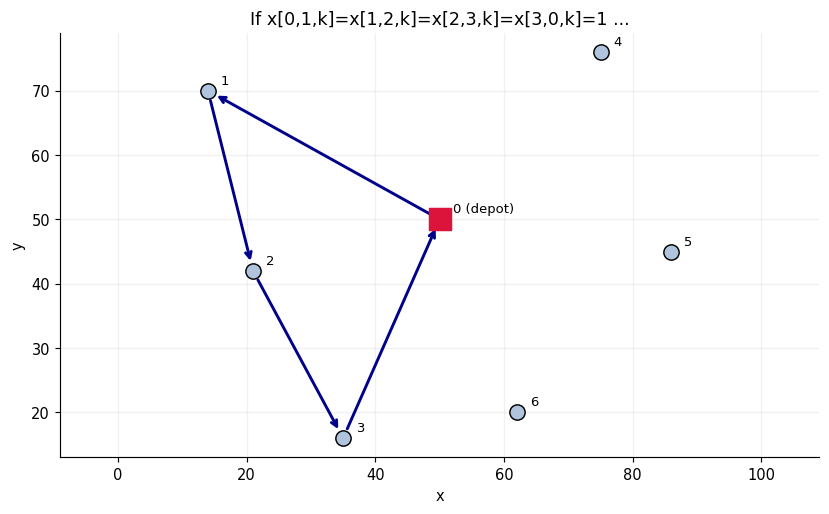

Active arcs in this illustrative route: [(0, 1), (1, 2), (2, 3), (3, 0)]


In [7]:
# Conceptual illustration drawn from the hand-written route [1,2,3].
path = [0, 1, 2, 3, 0]
xy = small.coordinates
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(xy[1:,0], xy[1:,1], s=110, color="lightsteelblue", edgecolor="black", zorder=3)
ax.scatter(xy[0,0], xy[0,1], s=230, marker="s", color="crimson", zorder=5)
for i,(x,y) in enumerate(xy):
    ax.text(x+2, y+1, f"{i}" + (" (depot)" if i==0 else ""), fontsize=9)
for a,b in zip(path[:-1], path[1:]):
    ax.annotate("", xy=xy[b], xytext=xy[a],
                arrowprops=dict(arrowstyle="->", color="darkblue", lw=2, shrinkA=7, shrinkB=7))
ax.set(xlabel="x", ylabel="y", title="If x[0,1,k]=x[1,2,k]=x[2,3,k]=x[3,0,k]=1 ...")
ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout(); plt.show()
print("Active arcs in this illustrative route:", list(zip(path[:-1], path[1:])))

## 3 · Objective: minimize the **total distance traveled by all trucks**

$$\boxed{\min_{x,y,z,u}\; Z=\sum_{k\in F}\sum_{(i,j)\in A}d_{ij}x_{ijk}}$$

Each selected arc incurs its cost *once*. We include depot-to-customer, customer-to-customer, and customer-to-depot travel. The objective sums over all trucks; it does **not** minimize the longest route, the number of trucks, or delivery time.

Even if coordinates are available, the matrix $D=[d_{ij}]$ is the authoritative cost input. A road-based matrix may be asymmetric ($d_{ij}\neq d_{ji}$); the formulation still works. Standard symmetric Euclidean CVRPLIB examples are only a special case.

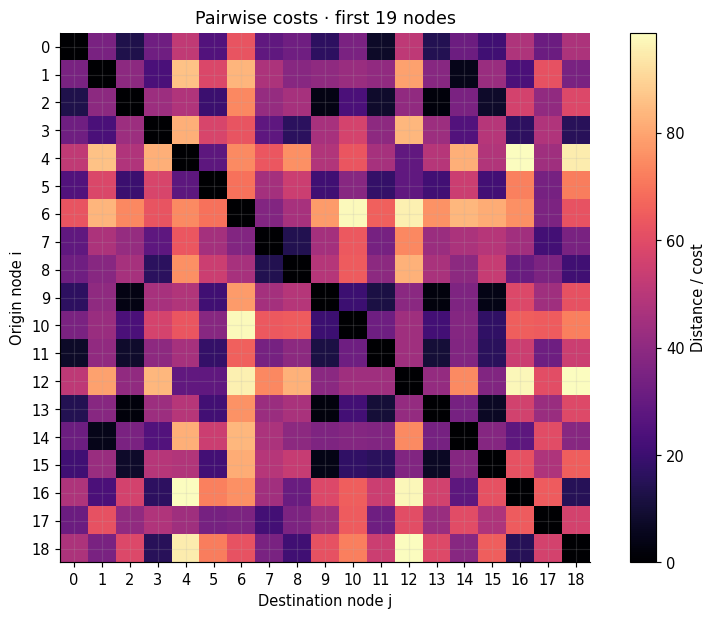

In [8]:
# Visualize the distance matrix. A small subset makes labels readable, while
# the full matrix remains available for mathematical evaluation and validation.
D = synthetic.distances
shown = min(D.shape[0], 19)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(D[:shown, :shown], cmap="magma", interpolation="nearest")
fig.colorbar(im, ax=ax, label="Distance / cost")
ax.set(xlabel="Destination node j", ylabel="Origin node i",
       title=f"Pairwise costs · first {shown} nodes")
ax.set_xticks(np.arange(shown)); ax.set_yticks(np.arange(shown))
plt.tight_layout(); plt.show()

## 4 · CVRPTW routing and capacity constraints (M0–M10; timing in §4.5)

Let $C=\{1,\dots,n\}$, $V=C\cup\{0\}$, $F=\{1,\dots,K\}$, and $A=\{(i,j)\in V^2:i\neq j\}$.

The confirmed formulation uses **at most K** vehicles. No constraint forces all trucks to operate. All share Q and the depot operating window.

### (M0) Objective

$$\min\sum_{k\in F}\sum_{(i,j)\in A}d_{ij}x_{ijk}.$$

### (M1) Each customer is assigned exactly once

$$\boxed{\sum_{k\in F} y_{ik}=1\quad\forall i\in C.}$$

### (M2–M3) Each assigned truck enters and leaves its customers exactly once

$$\boxed{\sum_{j\in V\setminus\{i\}}x_{ijk}=y_{ik}
\quad\forall i\in C,\;\forall k\in F,}$$

$$\boxed{\sum_{j\in V\setminus\{i\}}x_{jik}=y_{ik}
\quad\forall i\in C,\;\forall k\in F.}$$

Together with (M1), these encode visit-once and conservation of flow.

### (M4–M5) Every used truck departs from and returns to the depot

$$\boxed{\sum_{j\in C}x_{0jk}=z_k\quad\forall k\in F,}$$

$$\boxed{\sum_{i\in C}x_{i0k}=z_k\quad\forall k\in F.}$$

A truck with $z_k=0$ has no assigned customers or selected arcs.

### (M6) Capacity of each truck

$$\boxed{\sum_{i\in C}q_i y_{ik}\le Q z_k\quad\forall k\in F.}$$

Since each customer has one assigned truck, no demand is split across trucks.

### (M7–M9) Order-based Miller–Tucker–Zemlin (MTZ) subtour elimination

$$\boxed{y_{ik}\le u_{ik}\le n y_{ik}
\quad\forall i\in C,\;\forall k\in F,}$$

$$\boxed{u_{jk}\ge u_{ik}+1-(n+1)(1-x_{ijk})
\quad\forall i,j\in C,\;i\ne j,\;\forall k\in F.}$$

When $x_{ijk}=1$, order must increase by at least 1. A cycle of customers would require $u_{i_1,k}<u_{i_2,k}<\cdots<u_{i_m,k}<u_{i_1,k}$, which is impossible. When $x_{ijk}=0$, the lower bound is redundant because $u_{ik}\le n$ and $u_{jk}\ge0$; the **valid big-$M$ coefficient is $n+1$**.

**Strength:** this order formulation still eliminates disconnected cycles if some demands $q_i=0$, unlike a naïve positive-demand load-based MTZ proof.

### (M10) Decision domains / forbidden self-loops

$$\boxed{x_{ijk}\in\{0,1\}\quad\forall (i,j)\in A,\ k\in F,}$$
$$\boxed{y_{ik}\in\{0,1\}\quad\forall i\in C,\ k\in F,}$$
$$\boxed{z_k\in\{0,1\}\quad\forall k\in F,}$$
$$\boxed{u_{ik}\in\mathbb R_{\ge0}\quad\forall i\in C,\ k\in F.}$$

There are **no** $x_{iik}$ variables (or equivalently, set them to 0). We assume all input distances are finite and all truck capacities identical.

### Optional (not required): symmetry reduction

$$z_k\ge z_{k+1}\quad (k=1,\dots,K-1).$$

Trucks are interchangeable, so unused trucks can be placed after active trucks. This changes *which truck label* is used, not the objective or set of physical routes. It is an optional improvement to a future ILP implementation, not a needed feasibility rule.

### 4.1 · Constraint-to-business-rule traceability

| Mathematical rule | Operational meaning | Failure if omitted |
|---|---|---|
| M1: $\sum_k y_{ik}=1$ | Every customer served once | Skipped or multiply assigned customers |
| M2–M3: incoming/outgoing $=y_{ik}$ | Continuity and visit-once per truck | Fragmented or unmatched travel arcs |
| M4–M5: depot degree $=z_k$ | Active route begins and ends at depot | Open routes / unused truck inconsistencies |
| M6: $\sum_i q_i y_{ik}\le Qz_k$ | Payload capacity | Overloaded trucks |
| M7–M9: $u$ bounds and increasing order | No customer-only cycles | Disconnected subtours |
| M10: binary domains and $i\ne j$ | Yes/no travel decisions and no self-loops | Fractional or meaningless trips |

These equations establish routing and capacity. Section 4.5 adds service duration, hard service-start windows, and depot schedules. No fixed route-length constraint is assumed.

### 4.2 · Visual proof: why flow constraints alone do not eliminate subtours

Imagine one truck with a valid depot loop $0\to1\to2\to0$ and a disconnected customer loop $3\to4\to3$. Every customer still has one incoming and one outgoing arc, but the second loop is unreachable from the depot. It is **not** a valid delivery plan.

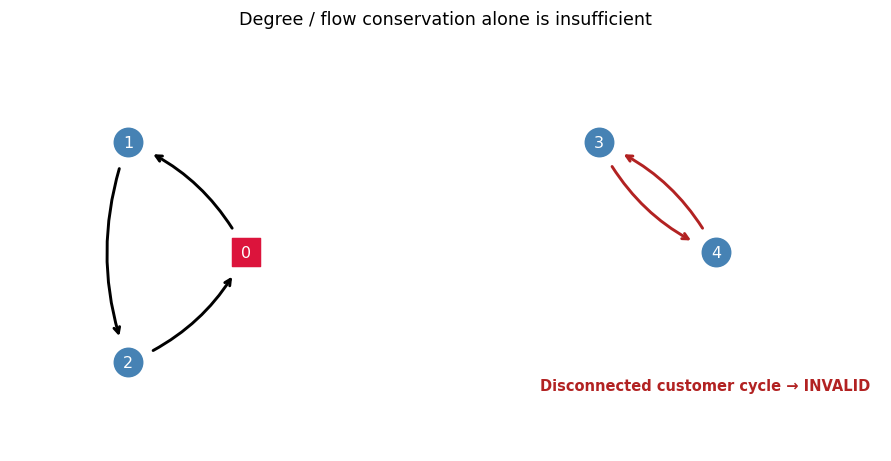

In [9]:
# Purely schematic node positions; edges deliberately exhibit a bad subtour.
positions = {0:(0,0), 1:(-1,1), 2:(-1,-1), 3:(3,1), 4:(4,0)}
bad_arcs = [(0,1),(1,2),(2,0),(3,4),(4,3)]
fig, ax = plt.subplots(figsize=(9, 4.5))
for v,(x,y) in positions.items():
    ax.scatter([x],[y],s=380,marker="s" if v==0 else "o",
               color="crimson" if v==0 else "steelblue",zorder=5)
    ax.text(x,y,str(v),color="white",ha="center",va="center",fontsize=11,zorder=6)
for a,b in bad_arcs:
    ax.annotate("", xy=positions[b], xytext=positions[a],
                arrowprops=dict(arrowstyle="->", lw=2,
                                color="firebrick" if a>=3 else "black",
                                connectionstyle="arc3,rad=0.19", shrinkA=19, shrinkB=19))
ax.text(2.5,-1.25,"Disconnected customer cycle → INVALID",color="firebrick",weight="bold")
ax.set(title="Degree / flow conservation alone is insufficient", xlim=(-2,5.4),ylim=(-1.8,2))
ax.axis("off")
plt.tight_layout(); plt.show()

### 4.3 · Why MTZ eliminates the disconnected cycle

If the bad tour uses arcs $3\to4$ and $4\to3$ for truck $k$, the order equations imply

$$u_{4k}\ge u_{3k}+1\quad\text{and}\quad
u_{3k}\ge u_{4k}+1.$$

Adding gives $0\ge2$, a contradiction. This argument applies to any customer-only cycle, even with zero-demand customers.

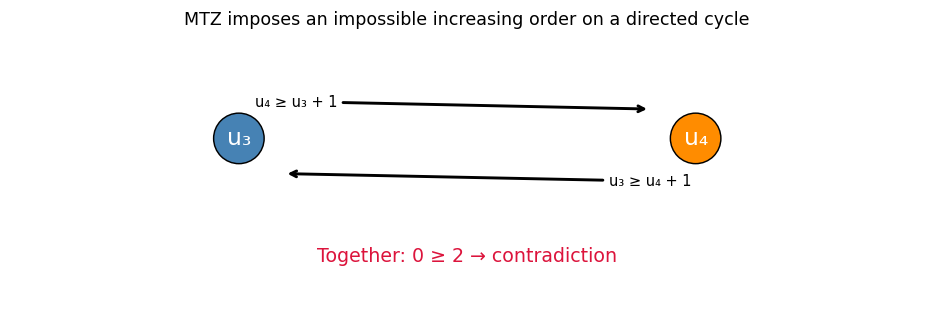

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.scatter([1,3], [1,1], s=1200, c=["steelblue","darkorange"], edgecolor="black")
ax.text(1,1,"u₃",color="white",ha="center",va="center",fontsize=16)
ax.text(3,1,"u₄",color="white",ha="center",va="center",fontsize=16)
ax.annotate("u₄ ≥ u₃ + 1",(2.8,1.25),(1.25,1.25),
            arrowprops={"arrowstyle":"->","lw":2},ha="center",va="bottom")
ax.annotate("u₃ ≥ u₄ + 1",(1.2,.70),(2.8,.70),
            arrowprops={"arrowstyle":"->","lw":2},ha="center",va="top")
ax.text(2,-.05,"Together: 0 ≥ 2 → contradiction",ha="center",color="crimson",fontsize=13)
ax.set(xlim=(0,4),ylim=(-.5,1.9),title="MTZ imposes an impossible increasing order on a directed cycle")
ax.axis("off")
plt.tight_layout(); plt.show()

### 4.4 · Why this formulation is sufficient and necessary

**(Necessary)** Take any physically feasible CVRPTW solution. Assign $z_k=1$ exactly for used trucks; set $y_{ik}=1$ exactly on the truck that serves customer $i$; set $x_{ijk}=1$ on consecutive route arcs, including the depot legs; set $u_{ik}$ to the position (1,2,...) of $i$ on truck $k$, or 0 when unassigned. All the equations hold.

**(Sufficient)** M1 assigns every customer to exactly one truck; M2/M3 force exactly one incoming and outgoing arc for the assigned customer; M4/M5 give each used truck exactly one depot departure and return; M7–M9 forbid every customer-only subtour. Hence the selected arcs for each used truck form exactly one connected directed route from and back to the depot. M6 enforces capacity. Therefore every feasible model assignment corresponds to a route satisfying the routing and capacity constraints.

**Timing requirement:** Section 4.5 must also hold for a complete CVRPTW solution.

**Representation limitation:** these statements assume all valid required arcs can be represented in $A$ and each distance is well-defined. In this notebook the full directed graph is used. The model does not imply symmetry or a triangle inequality unless the data supply them.

### 4.5 · Complete static CVRPTW MILP: temporal extension

Retain **all** M0–M10 above, including continuous order variables u, binary x/y/z, forbidden self-loops and the distance objective. Add y_ik≤z_k explicitly. This is MILP (mixed-integer PLNE terminology), not an all-integer model. Costs d_ij and travel times t_ij are separate static parameters; for the selected CVRPLIB cases t=d, each Euclidean arc truncated to one decimal. Coordinate symbols are p_i=(X_i,Y_i), distinct from window bounds.

| Data | Definition |
|---|---|
| [a_i,b_i], s_i | Hard service-start interval and nonnegative service duration, each customer |
| [a_0,b_0], H=b_0 | Depot opening, latest return and finite time horizon |
| d_ij,t_ij | Finite nonnegative static distance and travel time for each allowed arc |
| Input domains | 0≤a_i≤b_i, 0≤a_0≤H, s_i≥0, depot s_0=0; one depot |

| New variables | Domain and meaning |
|---|---|
| A_ik, S_ik, D_ik | Arrival, service start, departure from customer i by vehicle k |
| W_ik=S_ik−A_ik | Derived waiting, nonnegative |
| T_k,R_k | Separate departure from and return to depot; do not reuse one depot time variable |

All times use **benchmark elapsed-time units**, not assumed minutes or time zones. Zero all schedule variables for inactive assignments/vehicles. For all i∈C,k∈F:

$$0\le A_{ik},S_{ik},D_{ik}\le H y_{ik},\quad y_{ik}\le z_k.\tag{TW1}$$
$$a_i y_{ik}\le S_{ik}\le b_i y_{ik},\quad S_{ik}\ge A_{ik},\quad D_{ik}=S_{ik}+s_i y_{ik}.\tag{TW2}$$
$$a_0z_k\le T_k\le R_k\le H z_k.\tag{TW3}$$

For any customer-to-customer arc i→j, enforce exact physical arrival by two-sided activation:
$$-M_{ij}(1-x_{ijk})\le A_{jk}-D_{ik}-t_{ij}\le M_{ij}(1-x_{ijk}).\tag{TW4}$$
Use distinct depot legs:
$$-M_{0j}(1-x_{0jk})\le A_{jk}-T_k-t_{0j}\le M_{0j}(1-x_{0jk}),\tag{TW5}$$
$$-M_{i0}(1-x_{i0k})\le R_k-D_{ik}-t_{i0}\le M_{i0}(1-x_{i0k}).\tag{TW6}$$

**Valid finite bounds:** choose M_ij=H+t_ij. Each difference is between −H−t_ij and H−t_ij because all its time variables lie in [0,H]; hence both inequalities deactivate when x=0. When x=1 equality enforces sufficient travel exactly, with any waiting represented at the destination. No arbitrary huge constant is needed. MTZ still uses its separately derived n+1 coefficient. Omit unreachable arcs rather than putting infinity in M. Retain MTZ even for zero travel/service or coincident coordinates; temporal ordering alone need not exclude zero-time cycles.

**Window interpretation:** arrival 30, opening 40, closing 50, service 15 → wait 10, start 40, depart 55 is allowed if the remaining route returns before depot close. Arrival 51 is infeasible. Completion after b_i is permitted; no service **starts** outside [a_i,b_i]. If a_i>H or service cannot finish before return, the relevant assignment is infeasible; do not clip raw windows to make it pass.

**Correctness:** any valid scheduled depot tour induces M0–M10 and TW1–TW6, with u equal to visit position. Conversely, routing constraints/MTZ give one connected tour per active truck; TW4–TW6 enforce each actual travel leg, TW2 enforces service and nonnegative waiting, TW3 enforces depot opening/return and zero inactive times. A single depot time would incorrectly constrain a positive-duration cycle, which is why T and R differ.

The MILP allows extra pre-service waiting. Because travel is static and distance is the objective, every feasible route sequence also admits its earliest schedule: set T=a_0 and S=max(A,a_i) recursively. This cannot make service or return later, so checking that schedule suffices to establish temporal feasibility of a supplied order. It does not construct or optimize a route. Inactive trucks have no schedule, no arcs and zero cost.

**Domains and scope:** A,S,D,T,R are continuous nonnegative variables; W=S−A is derived, u is continuous with M7–M9 bounds, x/y/z are binary, and no self-loops exist. TW4 applies only to distinct customer pairs; TW5/TW6 cover depot legs. All input times are nonnegative finite elapsed units. Each vehicle may choose T within the common depot window; default checker departure a_0 supplies a feasible representative, not an optimization of departure. Later feasible departures are explicitly supported and tested. Symmetry reduction is optional because vehicles share every modeled constraint. The geometry/capacity examples above isolate the routing foundation; the synthetic examples below check the full temporal extension.


## 5 · Complexity: static CVRPTW is NP-hard

Start with finite nonnegative rational TSP distances on n+1 nodes and a distance budget B. Keep those distances and use t=d, one truck, unit customer demands, Q=n, zero service and all windows [0,H], with H=(n+1) max(d_ij) (H=0 is allowed for the all-zero degenerate case). Any simple depot-returning tour has at most n+1 arcs and fits this horizon. The construction has polynomial encoding size. A CVRPTW route of distance at most B exists exactly when the original TSP tour does. Thus optimization is NP-hard. A supplied route list has a polynomial-time exact rational earliest-service/capacity/cost verification, so the finite-rational distance-budget decision variant is NP-complete.

The formulation has O(K n²) routing/MTZ and temporal constraints and O(Kn) schedule variables. This counts model size, not execution time. Heuristic or metaheuristic research belongs to a later phase; none is chosen here. The data top out at 1,000 customers and cannot alone establish several-thousand-customer capability.


## 6 · Independent feasibility validator (not an optimization algorithm)

A **route list** is a set of customer sequences. Example: `[[1, 2], [3, 4]]` represents $0\to1\to2\to0$ and $0\to3\to4\to0$. The depot is inserted by the checker and therefore must **not** appear within any customer sequence.

The following functions do **not search for routes**. They only assess routes provided by a human or benchmark source, identifying customer coverage, duplicated visits, capacity, depot, fleet and distance issues.

In [11]:
@dataclass
class ValidationResult:
    feasible: bool
    problems: list[str]
    route_loads: list[float]
    route_distances: list[float]
    total_distance: float
    customers_seen: int


def validate_routes(instance: CVRPInstance, routes: list[list[int]]) -> ValidationResult:
    """Validate an EXISTING route list; it never modifies or optimizes it.

    Every route is a customer-only sequence. It must contain valid integer IDs
    from 1...n; the depot (0) is implicit. Empty routes are ignored, so an
    available but unused truck is permitted. A vehicle is assigned at most one
    nonempty sequence, matching the fleet model.
    """
    issues = instance.check_input()
    if issues:
        return ValidationResult(False, issues, [], [], float("nan"), 0)
    loads, route_distances, visited = [], [], []
    active_routes = [r for r in routes if len(r) > 0]
    if len(active_routes) > instance.max_vehicles:
        issues.append(f"Fleet limit: used {len(active_routes)} > K={instance.max_vehicles}.")
    for vehicle_idx, route in enumerate(active_routes, start=1):
        invalid = [node for node in route if type(node) not in (int, np.int32, np.int64)
                   or not (1 <= int(node) <= instance.n_customers)]
        if invalid:
            issues.append(f"Route {vehicle_idx}: invalid customer/depot IDs: {invalid}.")
            loads.append(float("nan")); route_distances.append(float("nan"))
            continue
        visited.extend(route)
        load = float(np.sum(instance.demands[route]))
        loads.append(load)
        if load > instance.capacity + 1e-9:
            issues.append(f"Route {vehicle_idx}: load {load:g} exceeds Q={instance.capacity:g}.")
        path = [0] + list(route) + [0]
        route_distance = sum(float(instance.distances[a, b])
                             for a, b in zip(path[:-1], path[1:]))
        route_distances.append(route_distance)
    counts = Counter(visited)
    duplicate = sorted(i for i, number in counts.items() if number > 1)
    missing = sorted(set(range(1, instance.n_customers + 1)) - set(visited))
    if duplicate:
        issues.append(f"Duplicate customer(s): {duplicate}.")
    if missing:
        issues.append(f"Missing customer(s): {missing}.")
    total = float(sum(route_distances))
    return ValidationResult(
        feasible=not issues, problems=issues, route_loads=loads,
        route_distances=route_distances, total_distance=total,
        customers_seen=len(visited),
    )


def summarize_route_check(instance: CVRPInstance, routes: list[list[int]]) -> pd.DataFrame:
    result = validate_routes(instance, routes)
    print("Feasible:", result.feasible)
    print("Distance:", round(result.total_distance, 3))
    print("Issues:", result.problems if result.problems else "none")
    table = pd.DataFrame({
        "Truck": range(1, len(result.route_loads) + 1),
        "Load": result.route_loads,
        "Capacity": instance.capacity,
        "Distance": result.route_distances,
    })
    display(table)
    return table

small_check_table = summarize_route_check(small, EXAMPLE_ROUTES)
assert validate_routes(small, EXAMPLE_ROUTES).feasible

Feasible: True
Distance: 272.665
Issues: none


,Truck,Load,Capacity,Distance
0,1,15.0,16.0,136.735714
1,2,12.0,16.0,135.929582


### 6.1 · Plot two explicitly supplied hand-written routes

The plotted routes are **not the solution of an optimizer**. They demonstrate exactly how the mathematical model interprets a valid route list and its distance cost.

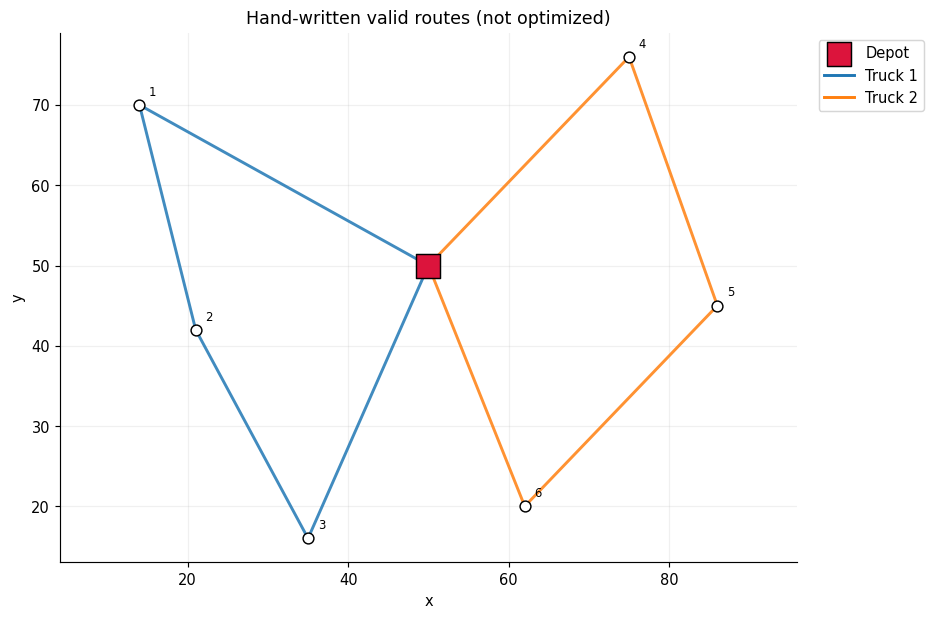

In [12]:
def plot_routes(instance: CVRPInstance, routes: list[list[int]], title: str):
    """Draw only user-supplied or reference routes. No route construction."""
    if instance.coordinates is None:
        print("Skipping route drawing: this instance does not include coordinates.")
        return
    fig, ax = plt.subplots(figsize=(9, 6))
    xy = instance.coordinates
    colors = plt.get_cmap("tab10")
    ax.scatter(xy[1:,0], xy[1:,1], s=55, color="white",
               edgecolor="black", zorder=5)
    ax.scatter(xy[0,0], xy[0,1], s=250, marker="s",
               color="crimson", edgecolor="black", zorder=6, label="Depot")
    for i,(x,y) in enumerate(xy[1:],start=1):
        if instance.n_customers <= 45:
            ax.text(x+1.2, y+1.2, str(i), fontsize=8)
    for k, route in enumerate(routes):
        if not route:
            continue
        path = [0] + list(route) + [0]
        color = colors(k % 10)
        for a,b in zip(path[:-1],path[1:]):
            ax.plot(xy[[a,b],0],xy[[a,b],1], color=color,alpha=.85,lw=2)
        ax.plot([],[],color=color,lw=2,label=f"Truck {k+1}")
    ax.set(xlabel="x",ylabel="y",title=title)
    ax.set_aspect("equal",adjustable="datalim")
    ax.legend(loc="upper left",bbox_to_anchor=(1.02,1))
    plt.tight_layout(); plt.show()

plot_routes(small, EXAMPLE_ROUTES, "Hand-written valid routes (not optimized)")

### 6.2 · Load profiles and capacity slack

Because the rules constrain **per-route demand**, not aggregate demand alone, it is useful to visualize individual vehicle loads and unused capacity. All loads below are calculated from the hand-written route list.

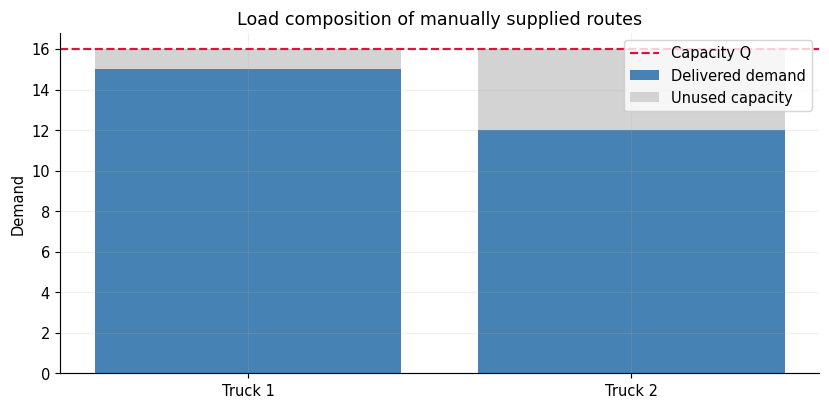

In [13]:
result_small = validate_routes(small, EXAMPLE_ROUTES)
loads = np.array(result_small.route_loads)
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(loads))
ax.bar(x, loads, label="Delivered demand", color="steelblue")
ax.bar(x, small.capacity - loads, bottom=loads, label="Unused capacity", color="lightgray")
ax.axhline(small.capacity, color="crimson", linestyle="--", label="Capacity Q")
ax.set_xticks(x, [f"Truck {i+1}" for i in x])
ax.set(ylabel="Demand", title="Load composition of manually supplied routes")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

### 6.3 · Test **invalid** user-supplied routes

These tests are deliberate counterexamples: omitted customers, a duplicate delivery, fleet overuse, and a load exceeding $Q$. They verify that the checker rejects each violation and explain the business consequence.

,Scenario,Feasible,Errors,Reason
0,valid manual routes,True,0,—
1,one customer missing,False,1,Missing customer(s): [6].
2,duplicate customer,False,2,Route 2: load 18 exceeds Q=16.; Duplicate cust...
3,over-capacity route,False,1,Route 1: load 22 exceeds Q=16.
4,depot used as customer,False,2,Route 1: invalid customer/depot IDs: [0].; Mis...
5,too many trucks,False,1,Fleet limit: used 4 > K=3.


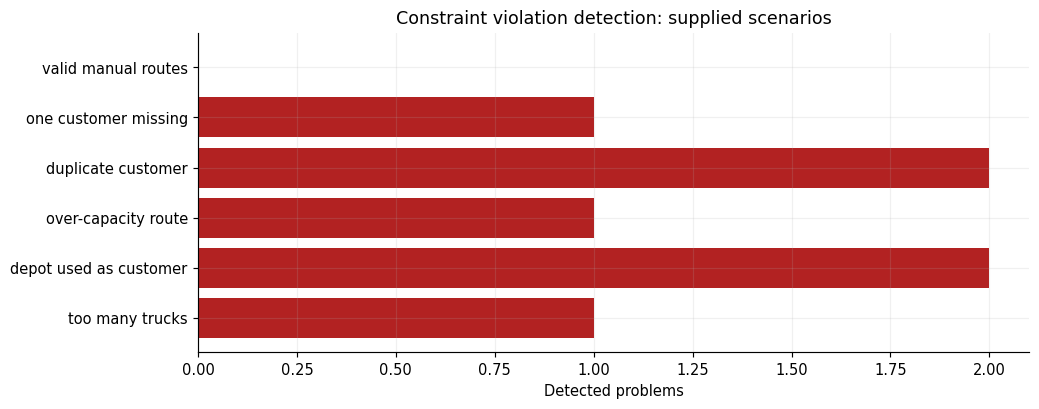

In [14]:
# Each case is explicitly constructed to violate a particular rule.
# Notice: test cases change the INPUT ROUTES, not the solver (there is none).
cases = {
    "valid manual routes": [[1,2,3], [4,5,6]],
    "one customer missing": [[1,2,3], [4,5]],
    "duplicate customer": [[1,2,3], [4,5,6,1]],
    "over-capacity route": [[1,2,3,4], [5,6]],
    "depot used as customer": [[0,1,2,3], [4,5,6]],
    "too many trucks": [[1],[2],[3],[4,5,6]],
}
case_rows = []
for name, routes in cases.items():
    result = validate_routes(small, routes)
    case_rows.append({"Scenario":name,"Feasible":result.feasible,
                      "Errors":len(result.problems),
                      "Reason":"; ".join(result.problems) if result.problems else "—"})
scenario_table = pd.DataFrame(case_rows)
display(scenario_table)
assert scenario_table["Feasible"].tolist() == [True,False,False,False,False,False]

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(scenario_table["Scenario"], scenario_table["Errors"],
        color=["forestgreen" if good else "firebrick" for good in scenario_table["Feasible"]])
ax.set(xlabel="Detected problems", title="Constraint violation detection: supplied scenarios")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

### 6.4 · Reconstruct model variables from supplied routes, then verify the equations

A stronger check does not merely examine routes. It builds explicit $x$, $y$, $z$, and $u$ arrays from a **given** route list, and directly evaluates the ILP equations, including every MTZ inequality. This is useful for catching errors in the proposed mathematical notation **without running an optimizer**.

In [15]:
def certify_model_equations(instance: CVRPInstance, routes: list[list[int]]) -> dict:
    """Check every mathematical condition on a PROVIDED valid-route candidate.

    This is an exhaustive evaluator for equations M1-M10 on the input
    assignment; it is NOT a general ILP solver (no search, no branching,
    no route optimization). O(K*n^2) time is acceptable for small examples.
    """
    n, K = instance.n_customers, instance.max_vehicles
    V = n + 1
    if len([r for r in routes if r]) > K:
        raise ValueError("Cannot encode more routes than available trucks")
    x = np.zeros((K, V, V), dtype=int)
    y = np.zeros((K, V), dtype=int)
    z = np.zeros(K, dtype=int)
    u = np.zeros((K, V), dtype=float)
    active = [r for r in routes if r]
    for k, route in enumerate(active):
        z[k] = 1
        for position, customer in enumerate(route, start=1):
            if customer < 1 or customer > n:
                raise ValueError("Invalid customer ID")
            y[k, customer] = 1
            u[k, customer] = float(position)
        full_path = [0] + route + [0]
        for i, j in zip(full_path[:-1], full_path[1:]):
            x[k, i, j] = 1

    check = {}
    check["M1: each customer once"] = bool(np.all(y[:,1:].sum(axis=0) == 1))
    check["M2: outbound = assignment"] = bool(np.all(x[:,:, :].sum(axis=2)[:,1:] == y[:,1:]))
    check["M3: inbound = assignment"] = bool(np.all(x.sum(axis=1)[:,1:] == y[:,1:]))
    check["M4: leave depot"] = bool(np.all(x[:,0,1:].sum(axis=1) == z))
    check["M5: return to depot"] = bool(np.all(x[:,1:,0].sum(axis=1) == z))
    check["M6: capacities"] = bool(np.all(y[:,1:] @ instance.demands[1:] <= instance.capacity*z + 1e-9))
    check["M7: u lower bound"] = bool(np.all(y[:,1:] <= u[:,1:] + 1e-9))
    check["M8: u upper bound"] = bool(np.all(u[:,1:] <= n*y[:,1:] + 1e-9))
    mtz_ok = True
    for k in range(K):
        for i in range(1,V):
            for j in range(1,V):
                if i != j:
                    lhs = u[k,j]
                    rhs = u[k,i] + 1 - (n+1)*(1-x[k,i,j])
                    if lhs < rhs - 1e-9:
                        mtz_ok = False
                        break
    check["M9: subtour (MTZ)"] = mtz_ok
    check["M10: no self-loop"] = bool(np.all(np.diagonal(x,axis1=1,axis2=2)==0))
    cost = float(np.sum(x * instance.distances[None,:,:]))
    route_cost = validate_routes(instance, routes).total_distance
    check["Objective equals route cost"] = bool(np.isclose(cost,route_cost))
    return {"checks":check, "all_hold":all(check.values()), "cost":cost,
            "x":x,"y":y,"z":z,"u":u}

certificate = certify_model_equations(small, EXAMPLE_ROUTES)
display(pd.DataFrame({"Equation": list(certificate["checks"]),
                      "Holds": list(certificate["checks"].values())}))
assert certificate["all_hold"]
print("Verified ILP objective:", round(certificate["cost"],3))

,Equation,Holds
0,M1: each customer once,True
1,M2: outbound = assignment,True
2,M3: inbound = assignment,True
3,M4: leave depot,True
4,M5: return to depot,True
5,M6: capacities,True
6,M7: u lower bound,True
7,M8: u upper bound,True
8,M9: subtour (MTZ),True
9,M10: no self-loop,True


Verified ILP objective: 272.665


### 6.5 · What happens when demand is zero?

Zero-demand customers are legal inputs in the mathematical model. Subtour elimination **must still work**. Our visit-order-based MTZ uses $+1$ rather than $+q_i$ and is therefore not dependent on positive demands.

In [16]:
# Small zero-demand edge case: each customer still requires a visit.
zero_case = CVRPInstance(
    name="Zero-demand edge case",
    demands=np.array([0., 0., 0., 3.]), capacity=3., max_vehicles=2,
    distances=euclidean_cost_matrix(np.array([[0.,0.],[1.,0.],[2.,1.],[2.,2.]])),
    coordinates=np.array([[0.,0.],[1.,0.],[2.,1.],[2.,2.]]),
)
zero_routes = [[1,2,3]]   # Illustrative handwritten candidate.
print("Zero-demand case feasible:", validate_routes(zero_case,zero_routes).feasible)
print("MTZ and all model equations hold:", certify_model_equations(zero_case,zero_routes)["all_hold"])
assert certify_model_equations(zero_case,zero_routes)["all_hold"]

Zero-demand case feasible: True
MTZ and all model equations hold: True


## 8 · Parameter sensitivity without solving the CVRPTW

The following studies vary capacity, fleet size, customer count, and spatial distribution to illustrate necessary feasibility conditions and model size. They do not generate optimized routes.

### 8.1 · Capacity $Q$ versus the aggregate-demand fleet bound

For total demand $D$, $\lceil D/Q\rceil$ is a necessary lower bound on vehicles. Time windows can require more vehicles.

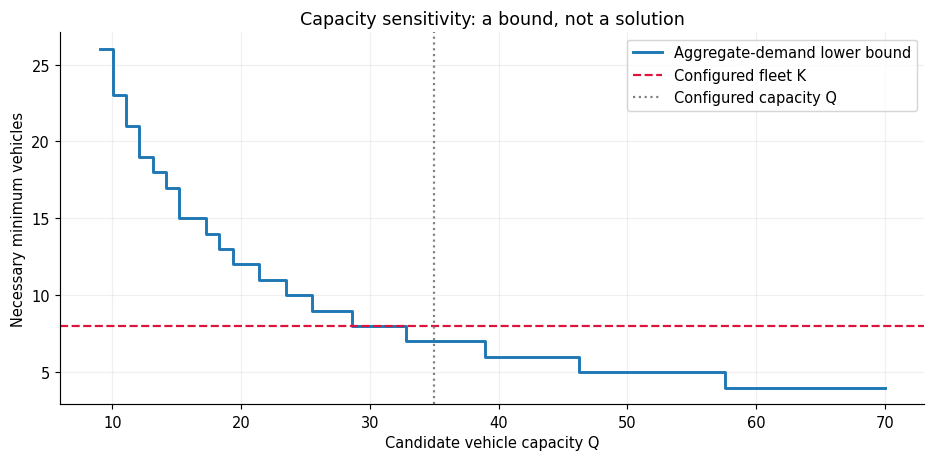

In [17]:
D_total = float(synthetic.demands[1:].sum())
max_q = float(synthetic.demands[1:].max())
# Study capacities from at least the largest individual demand up to an editable
# multiple of the configured capacity. These are experiments, not model constants.
cap_grid=np.linspace(max(1,max_q),max(max_q+1,2*SYNTHETIC.vehicle_capacity),60)
truck_lb=np.ceil(D_total/cap_grid)
fig,ax=plt.subplots(figsize=(9,4.5))
ax.step(cap_grid,truck_lb,where="post",lw=2,label="Aggregate-demand lower bound")
ax.axhline(SYNTHETIC.max_vehicles,color="crimson",linestyle="--",label="Configured fleet K")
ax.axvline(SYNTHETIC.vehicle_capacity,color="gray",linestyle=":",label="Configured capacity Q")
ax.set(xlabel="Candidate vehicle capacity Q",ylabel="Necessary minimum vehicles",
       title="Capacity sensitivity: a bound, not a solution")
ax.legend()
plt.tight_layout();plt.show()

### 8.2 · How does the full ILP formulation scale?

For a complete directed graph with $n$ customers and $K$ trucks, our formulation creates:

- $K(n+1)n$ binary arc variables $x$ (no diagonal),
- $Kn$ binary assignment variables $y$,
- $K$ binary vehicle-use variables $z$,
- $Kn$ continuous order variables $u$.

Therefore the number of binary variables is $K(n^2+2n+1)=K(n+1)^2$, and continuous variables number $Kn$. The number of order inequalities alone is $Kn(n-1)$ — quadratic in customers and linear in vehicles. This is why we **model with ILP now**, but should later use an efficient heuristic for large instances.

These are **representation sizes**, not execution time predictions and not experimental algorithm results.

In [18]:
def model_sizes(n: int, k: int) -> dict[str,int]:
    """Count decision variables and major constraint families algebraically."""
    if n<1 or k<1:
        raise ValueError("n and K must be positive")
    return {
        "arcs (binary)":k*(n+1)*n,
        "assignments (binary)":k*n,
        "vehicle-use (binary)":k,
        "order (continuous)":k*n,
        "MTZ pairwise inequalities":k*n*(n-1),
        "degree equalities":2*k*n,
        "customer assignment eqs":n,
        "depot equalities":2*k,
        "capacity inequalities":k,
        "order-bound inequalities":2*k*n,
    }

sizes=model_sizes(synthetic.n_customers,synthetic.max_vehicles)
display(pd.DataFrame(sizes.items(),columns=["Component","Count"]))
assert sizes["arcs (binary)"] == synthetic.max_vehicles*(synthetic.n_customers+1)*synthetic.n_customers
assert sum(sizes[k] for k in ["arcs (binary)","assignments (binary)","vehicle-use (binary)"]) == synthetic.max_vehicles*(synthetic.n_customers+1)**2

,Component,Count
0,arcs (binary),14448
1,assignments (binary),336
2,vehicle-use (binary),8
3,order (continuous),336
4,MTZ pairwise inequalities,13776
5,degree equalities,672
6,customer assignment eqs,42
7,depot equalities,16
8,capacity inequalities,8
9,order-bound inequalities,672


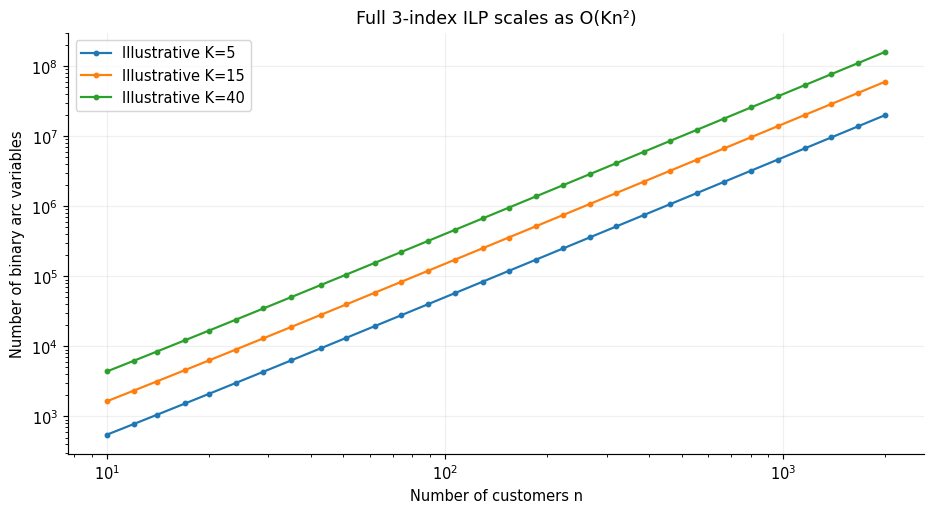

In [19]:
# Compare symbolic model sizes for three possible fleet-scaling scenarios.
n_grid=np.unique(np.geomspace(10,2000,num=30).astype(int))
fig,ax=plt.subplots(figsize=(9,5))
for assumed_K in (5,15,40):  # Scenario values only; not hard-coded fleet limits.
    arc_vars=[model_sizes(int(n),assumed_K)["arcs (binary)"] for n in n_grid]
    ax.plot(n_grid,arc_vars,marker=".",label=f"Illustrative K={assumed_K}")
ax.set(xlabel="Number of customers n",ylabel="Number of binary arc variables",
       title="Full 3-index ILP scales as O(Kn²)",xscale="log",yscale="log")
ax.legend()
plt.tight_layout();plt.show()

### 8.3 · Spatial distribution: uniform vs clustered customers

Customer geometry is part of the **input**, not a mathematical constraint: uniform and clustered instances can have the same number of customers, identical capacities and similar demand distributions, yet very different routing structure.

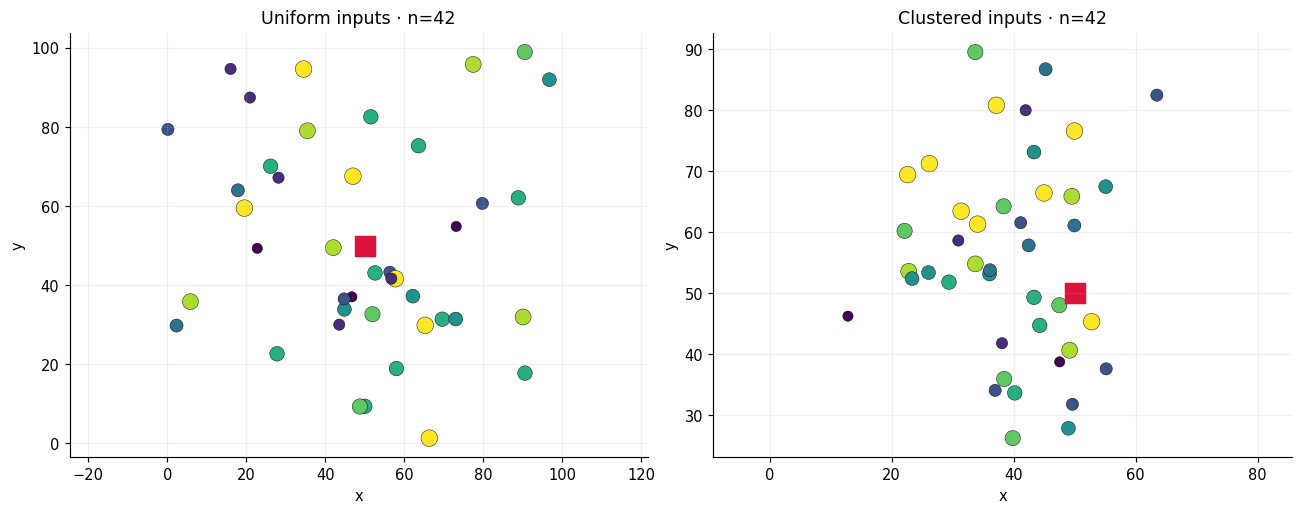

In [20]:
# Use the same configurable values and random seed, changing only layout.
from dataclasses import replace
uniform_demo = generate_synthetic(replace(SYNTHETIC, layout="uniform"))
clustered_demo = generate_synthetic(replace(SYNTHETIC, layout="clustered"))
fig,axs=plt.subplots(1,2,figsize=(12.5,5))
for ax,inst,label in zip(axs,[uniform_demo,clustered_demo],["Uniform", "Clustered"]):
    xy=inst.coordinates
    ax.scatter(xy[1:,0],xy[1:,1],s=40+10*inst.demands[1:],
               c=inst.demands[1:],cmap="viridis",edgecolor="black",lw=.3)
    ax.scatter([xy[0,0]],[xy[0,1]],s=200,marker="s",color="crimson")
    ax.set(xlabel="x",ylabel="y",title=f"{label} inputs · n={inst.n_customers}")
    ax.set_aspect("equal",adjustable="datalim")
plt.tight_layout();plt.show()

### 8.4 · Fleet-and-capacity necessary feasibility map

The heatmap below marks whether $KQ\ge\sum_i q_i$ — an **aggregate necessity test only**. A green cell means *not ruled out* by total capacity; it does **not** prove route feasibility. A red cell is definitely infeasible by this bound.

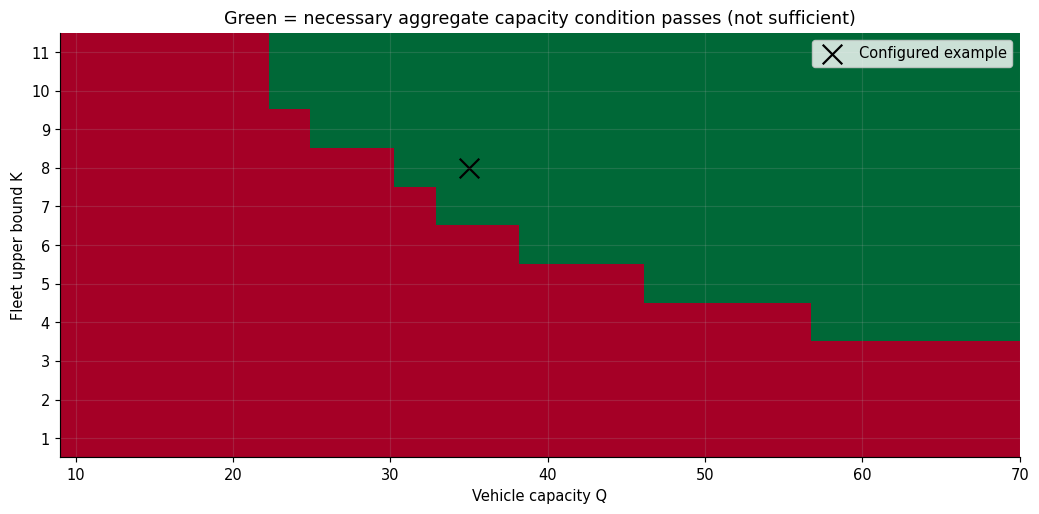

In [21]:
qsum=float(synthetic.demands[1:].sum())
max_q=float(synthetic.demands[1:].max())
K_values=np.arange(1,max(9,SYNTHETIC.max_vehicles+4))
Q_values=np.linspace(max(1,max_q),max(2*SYNTHETIC.vehicle_capacity,max_q+1),23)
feasible_capacity=np.array([[k*q>=qsum and q>=max_q for q in Q_values] for k in K_values])
fig,ax=plt.subplots(figsize=(10,5))
img=ax.imshow(feasible_capacity,aspect="auto",origin="lower",cmap="RdYlGn",
              interpolation="nearest",extent=[Q_values[0],Q_values[-1],K_values[0]-.5,K_values[-1]+.5])
ax.scatter([synthetic.capacity],[synthetic.max_vehicles],marker="x",s=180,
           color="black",label="Configured example")
ax.set(xlabel="Vehicle capacity Q",ylabel="Fleet upper bound K",
       title="Green = necessary aggregate capacity condition passes (not sufficient)")
ax.set_yticks(K_values)
ax.legend()
plt.tight_layout();plt.show()

## 9 · Edge cases and model boundaries

| Situation | Expected behavior |
| --- | --- |
| Zero demand | Customer still requires exactly one visit |
| Demand equal to capacity | That vehicle cannot carry another positive demand |
| Early arrival | Vehicle waits until the service window opens |
| Service start after closing | Route is infeasible |
| Late depot return | Route is infeasible |
| Unused vehicle | No assigned customers or arcs |
| Demand above fleet capacity | Instance is infeasible |

Capacity and customer coverage alone cannot establish feasibility: every route also needs a valid schedule.

## 10 · Load selected static CVRPTW files

The configurable root defaults to `data/benchmarks/vrptw/`. `load_cvrptw` below uses the default VRPLIB parser, checks the one-based disk IDs and keeps paired `.sol` labels unchanged. Missing files produce NOT RUN in normal mode and fail strict mode. No benchmark results are synthesized.


## 10A · Complete dataset and schedule validation

Use only the [PyVRP/Instances VRPTW collection](https://github.com/PyVRP/Instances/tree/main/VRPTW): 56 Solomon plus 300 Gehring–Homberger pairs, organized locally as Solomon/GH200/GH400/GH600/GH800/GH1000. Upstream 1,000-customer files are at the VRPTW root; the downloader places them in GH1000. N includes depot. Coordinates `(N,2)`, demands `(N,)`, windows `(N,2)`, service `(N,)`, distance/travel `(N,N)`, scalar K/Q. Scalar SERVICE_TIME expands to customers, with depot zero; a vector must explicitly satisfy depot zero. No assumed GPS, minutes or time zones.

The reusable, commented implementation is in `scripts/cvrptw_model.py`. Optional coordinates/IDs/integer-tenths caches are validated when supplied; route checking works without them. Static travel defaults to distance but is separately configurable. Missing **required** windows/service/data is an explicit error.

The selected disk labels are 1…N, depot 1 → internal 0; supplied `.sol` labels already equal internal customer indices. Never shift twice. DIMACS edge distances are truncated to tenths. Integer-coordinate square-root boundary correction avoids floating rounding at integer tenths. No epsilon promotes a below-boundary distance. Reference cost validation uses integer-tenths sums, not displayed rounded costs. All 356 references are audited when data are available, with hashes; the five plots/examples below are illustrations, not a chosen final test split or optimizer results.


In [22]:
# Reusable mathematical validation support, not an optimizer.
from scripts.cvrptw_model import (
    CVRPTWInstance, load_cvrptw, check_cvrptw, check_temporal_equations,
    normalize_service, dimacs_tenths, verify_collection, reproducibility_metadata,
)


In [23]:
metadata = reproducibility_metadata(DATA_ROOT, SYNTHETIC.seed)
display(metadata)
collection = verify_collection(DATA_ROOT, strict=STRICT_DATA)
print("Collection validation:", collection["status"], "checked pairs:", collection["checked"])
reference_audits = {}; records = []
if collection["status"] == "NOT RUN":
    print(collection["reason"])
else:
    print("Collection SHA-256:", collection["collection_sha256"])
    display(collection["results"].groupby("family").agg(pairs=("instance","count"), feasible=("feasible","all")))
    # Supplied illustrations only; no tuning or final benchmark selection.
    for family,name in [("Solomon","C101"),("Solomon","R101"),("Solomon","RC101"),("GH200","C1_2_1"),("GH1000","C1_10_1")]:
        inst=load_cvrptw(DATA_ROOT/family/f"{name}.vrp")
        ref=vrplib.read_solution(str(DATA_ROOT/family/f"{name}.sol"))
        routes=[list(r) for r in ref["routes"]]
        audit=check_cvrptw(inst,routes)
        assert audit["feasible"] and check_temporal_equations(inst,routes,audit)
        reference_audits[name]=(inst,routes,audit)
        records.append(dict(instance=name,customers=inst.n_customers,K=inst.max_vehicles,Q=inst.capacity,
            reference_routes=len(routes),distance=audit["distance"],supplied_cost=ref["cost"],feasible=True))
    display(pd.DataFrame(records))


{'python': '3.9.6 (default, Aug 25 2026, 21:26:21) \n[Clang 21.0.0 (clang-2100.3.34.2)]',
 'platform': 'macOS-27.0.1-arm64-arm-64bit',
 'seed': 2026,
 'packages': {'numpy': '2.0.2',
  'pandas': '2.3.3',
  'matplotlib': '3.9.4',
  'vrplib': '1.5.1'},
 'dataset_root': '/Users/denni/EcoRoute-CVRPTW/data/benchmarks/vrptw',
 'source_manifest': {'source': 'https://github.com/PyVRP/Instances',
  'archive_url': 'https://codeload.github.com/PyVRP/Instances/zip/refs/heads/main',
  'downloaded_utc': '2026-11-09T09:53:04.194430+00:00',
  'archive_sha256': '0b03cfecc42722379f99eaf9f52f6d103f3bbe6a3a0538877041a0ef6dfc052c',
  'problem_type': 'VRPTW (vehicle routing with time windows)',
  'families': {'Solomon': 56,
   'GH200': 60,
   'GH400': 60,
   'GH600': 60,
   'GH800': 60,
   'GH1000': 60},
  'total_instances': 356,
  'file_types': ['.vrp', '.sol']},
 'upstream_commit': 'not recorded by source manifest; use collection/per-file hashes'}

Collection validation: PASS checked pairs: 356
Collection SHA-256: 73cc107742d4d73761df1b92f204c62010198c575d1f40af73afb0bbca1a0549


,pairs,feasible
family,,
GH1000,60,True
GH200,60,True
GH400,60,True
GH600,60,True
GH800,60,True
Solomon,56,True


,instance,customers,K,Q,reference_routes,distance,supplied_cost,feasible
0,C101,100,25,200.0,10,827.3,827.3,True
1,R101,100,25,200.0,20,1637.7,1637.7,True
2,RC101,100,25,200.0,15,1619.8,1619.8,True
3,C1_2_1,200,50,200.0,20,2698.6,2698.6,True
4,C1_10_1,1000,250,200.0,100,42444.8,42444.8,True


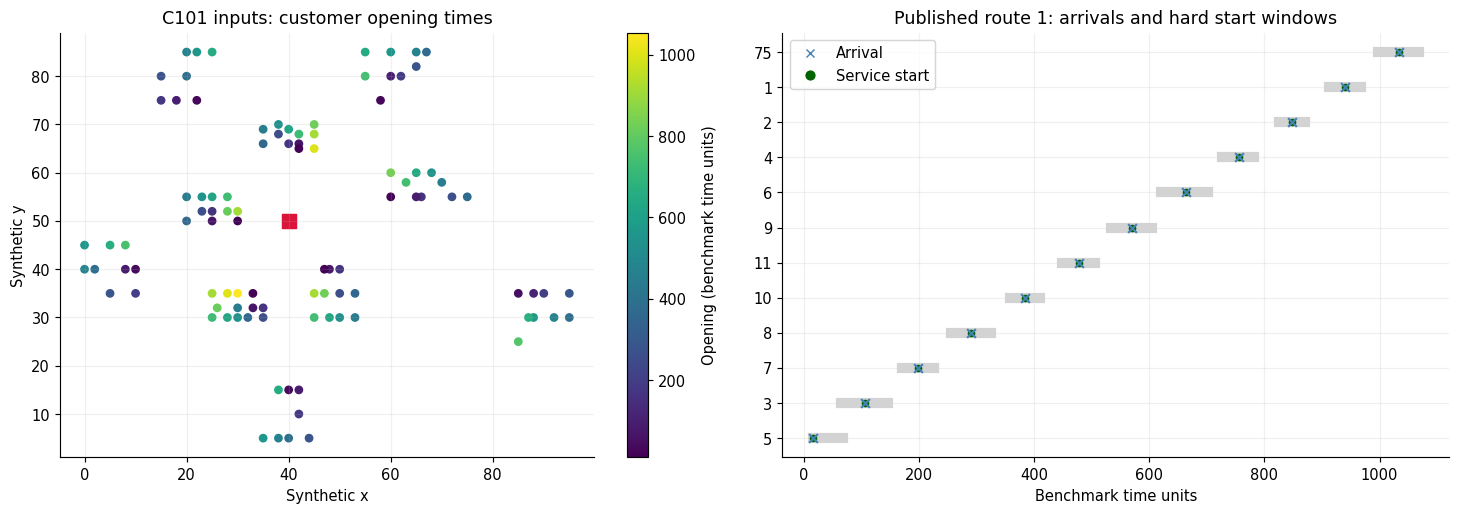

,customer,source_id,arrival,waiting,start,departure,lateness
0,5,6,15.1,0.0,15.1,105.1,0.0
1,3,4,106.1,0.0,106.1,196.1,0.0
2,7,8,198.1,0.0,198.1,288.1,0.0
3,8,9,290.9,0.0,290.9,380.9,0.0
4,10,11,384.5,0.0,384.5,474.5,0.0
5,11,12,477.5,0.0,477.5,567.5,0.0
6,9,10,570.6,0.0,570.6,660.6,0.0
7,6,7,662.8,0.0,662.8,752.8,0.0
8,4,5,755.0,0.0,755.0,845.0,0.0
9,2,3,848.6,0.0,848.6,938.6,0.0


,truck,departure,return_time,elapsed,driving,waiting,service,load,utilization,distance,depot_lateness
0,1,0.0,1139.4,1139.4,59.4,0.0,1080.0,180.0,0.90,59.4,0.0
1,2,0.0,815.8,815.8,95.8,0.0,720.0,190.0,0.95,95.8,0.0
2,3,0.0,1040.7,1040.7,50.7,0.0,990.0,170.0,0.85,50.7,0.0
3,4,0.0,907.0,907.0,97.0,0.0,810.0,200.0,1.00,97.0,0.0
4,5,0.0,1234.6,1234.6,64.6,0.0,1170.0,160.0,0.80,64.6,0.0
5,6,0.0,821.7,821.7,101.7,0.0,720.0,200.0,1.00,101.7,0.0
6,7,0.0,1049.3,1049.3,59.3,0.0,990.0,200.0,1.00,59.3,0.0
7,8,0.0,937.1,937.1,127.1,0.0,810.0,150.0,0.75,127.1,0.0
8,9,0.0,975.9,975.9,75.9,0.0,900.0,170.0,0.85,75.9,0.0
9,10,0.0,905.8,905.8,95.8,0.0,810.0,190.0,0.95,95.8,0.0


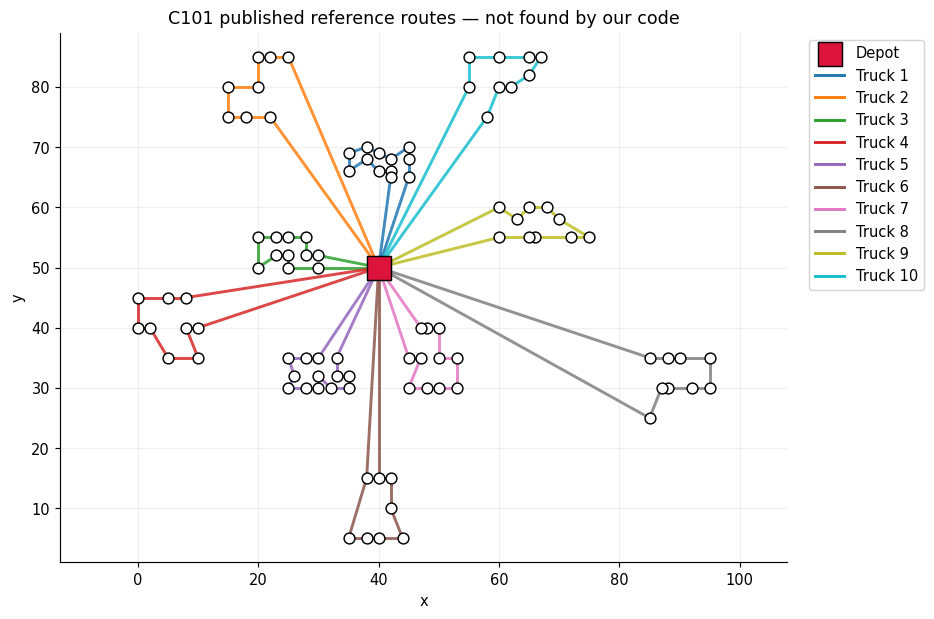

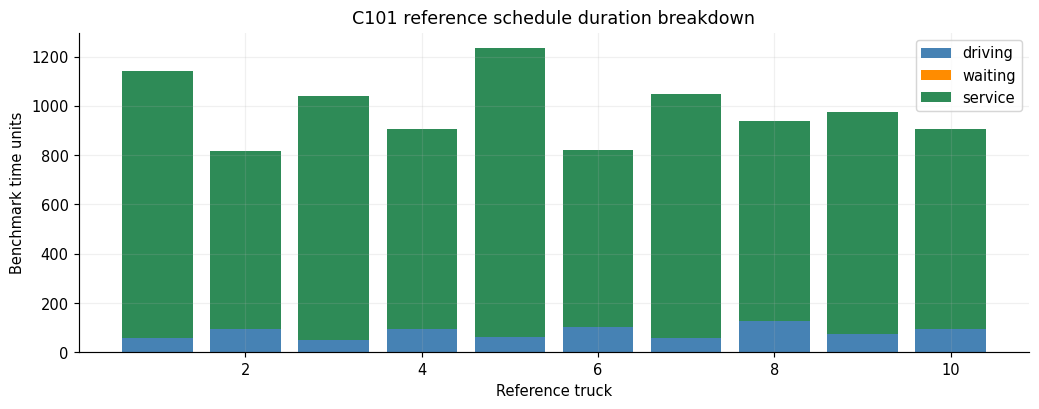

In [24]:
if not reference_audits:
    print("Reference plots: NOT RUN (collection unavailable)")
else:
    inst,routes,audit = reference_audits["C101"]
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    xy=inst.coordinates
    sc=axes[0].scatter(xy[1:,0],xy[1:,1],c=inst.time_windows[1:,0],cmap="viridis",s=25)
    axes[0].scatter(*xy[0],marker="s",color="crimson",s=100,label="Depot")
    axes[0].set(title="C101 inputs: customer opening times",xlabel="Synthetic x",ylabel="Synthetic y")
    fig.colorbar(sc,ax=axes[0],label="Opening (benchmark time units)")
    table=audit["schedules"][0]
    for j,row in enumerate(table.itertuples()):
        a,b=inst.time_windows[row.customer]
        axes[1].plot([a,b],[j,j],color="lightgray",lw=7)
        axes[1].scatter(row.arrival,j,marker="x",color="steelblue",zorder=4)
        axes[1].scatter(row.start,j,color="darkgreen",s=18,zorder=3)
    axes[1].plot([],[],"x",color="steelblue",label="Arrival")
    axes[1].plot([],[],"o",color="darkgreen",label="Service start")
    axes[1].set(yticks=range(len(table)),yticklabels=table.customer,title="Published route 1: arrivals and hard start windows",xlabel="Benchmark time units")
    axes[1].legend(); plt.tight_layout(); plt.show()
    display(table)
    display(audit["route_totals"])
    plot_routes(inst,routes,"C101 published reference routes — not found by our code")
    fig,ax=plt.subplots(figsize=(10,4))
    tot=audit["route_totals"]
    for label,color in [("driving","steelblue"),("waiting","darkorange"),("service","seagreen")]:
        bottom=np.zeros(len(tot)) if label=="driving" else tot.driving.to_numpy() if label=="waiting" else (tot.driving+tot.waiting).to_numpy()
        ax.bar(tot.truck,tot[label],bottom=bottom,label=label,color=color)
    assert np.allclose(tot.elapsed,tot.driving+tot.waiting+tot.service)
    ax.set(title="C101 reference schedule duration breakdown",xlabel="Reference truck",ylabel="Benchmark time units")
    ax.legend();plt.tight_layout();plt.show()


PASS: synthetic window/wait/service/depot/optional-field/shape/zero/asymmetric/fleet/capacity and full-arc equation checks.


,customer,source_id,arrival,waiting,start,departure,lateness
0,1,1,1.0,4.0,5.0,8.0,0.0


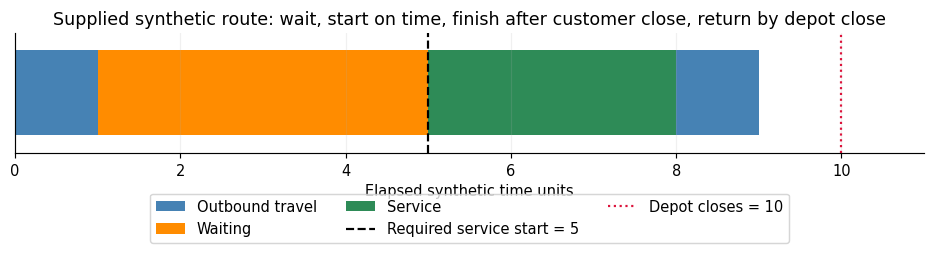

In [25]:
from dataclasses import replace
# Explicit input routes and schedules only: these tests never search for routes.
tiny=CVRPTWInstance(name="Waiting fixture",demands=[0,1],capacity=2,max_vehicles=2,
    distances=[[0,1],[1,0]],time_windows=[[0,10],[5,5]],service_durations=[0,3])
ta=check_cvrptw(tiny,[[1],[]])
assert ta["feasible"] and ta["schedules"][0].iloc[0].waiting==4
assert ta["schedules"][0].iloc[0].departure==8  # Completion after close is allowed.
assert check_temporal_equations(tiny,[[1],[]],ta)
assert check_cvrptw(tiny,[[1]],[4])["feasible"]  # Chosen later depot departure.
assert not check_cvrptw(tiny,[[1]],[5])["feasible"]
assert not check_cvrptw(tiny,[[1]],[-1])["feasible"]
assert not check_cvrptw(replace(tiny,time_windows=[[0,8],[5,5]]),[[1]])["feasible"]
assert check_cvrptw(replace(tiny,time_windows=[[2,9],[5,5]]),[[1]],[2])["feasible"] # Exact depot closing.
for routes in ([], [[1],[1]], [[0,1]], [[2]], [[True]], [[1.0]], [[1],[1],[1]]):
    assert not check_cvrptw(tiny,routes)["feasible"], routes
assert check_cvrptw(replace(tiny,demands=[0,0]),[[1]])["feasible"]
assert check_cvrptw(replace(tiny,capacity=1),[[1]])["feasible"]
zero=replace(tiny,distances=[[0,0],[0,0]],travel_times=[[0,0],[0,0]],service_durations=[0,0],time_windows=[[0,0],[0,0]])
assert check_cvrptw(zero,[[1]])["feasible"]
assert check_temporal_equations(zero,[[1]],check_cvrptw(zero,[[1]]))
assert check_cvrptw(replace(tiny,original_ids=[8,99]),[[1]])["schedules"][0].iloc[0].source_id==99
assert check_cvrptw(replace(tiny,coordinates=None,original_ids=None,distance_tenths=None),[[1]])["feasible"]
overload=CVRPTWInstance(name="Capacity fixture",demands=[0,1,1],capacity=1,max_vehicles=2,
    distances=np.ones((3,3))-np.eye(3),time_windows=[[0,10]]*3,service_durations=[0,0,0])
assert not check_cvrptw(overload,[[1,2]])["feasible"]
assert check_cvrptw(overload,[[1],[2]])["feasible"]
asym=replace(overload,capacity=2,distances=[[0,1,4],[2,0,1],[1,5,0]],travel_times=[[0,1,4],[2,0,1],[1,5,0]])
assert check_cvrptw(asym,[[1,2]])["distance"]==3
assert check_cvrptw(asym,[[2,1]])["feasible"] is False # Return 11 exceeds close 10.
assert np.array_equal(normalize_service(3,3),[0,3,3])
assert np.array_equal(normalize_service([0,2,4],3),[0,2,4])
assert dimacs_tenths([[0,0],[3,4]])[0,1]==50
assert dimacs_tenths([[0,0],[1,1]])[0,1]==14
bad_cases=[dict(demands=1),dict(demands=[0,float('nan')]),dict(max_vehicles=True),dict(max_vehicles=1.5),
    dict(capacity=0),dict(capacity=.5),dict(distances=[[0]]),dict(travel_times=[[0,-1],[1,0]]),
    dict(time_windows=None),dict(time_windows=[[0,10],[6,5]]),dict(service_durations=[1,3]),
    dict(service_durations=[0,-1]),dict(coordinates=[[0,0]]),dict(original_ids=[1,1]),
    dict(distance_tenths=[[0,20],[20,0]])]
for change in bad_cases:
    assert replace(tiny,**change).check_input(),change
    try: check_cvrptw(replace(tiny,**change),[[1]])
    except ValueError: pass
    else: raise AssertionError(change)
# Routing equations and all TW1–TW6 arcs, including unassigned nodes and unused trucks.
fixture=replace(overload,capacity=2,max_vehicles=3)
fa=check_cvrptw(fixture,[[1,2]])
assert certify_model_equations(fixture,[[1,2]])["all_hold"]
assert check_temporal_equations(fixture,[[1,2]],fa)
split=replace(overload,max_vehicles=3)
assert check_temporal_equations(split,[[1],[2]],check_cvrptw(split,[[1],[2]]))
import copy
corrupt=copy.deepcopy(fa);corrupt["schedules"][0].loc[0,"arrival"]+=.5
try: check_temporal_equations(fixture,[[1,2]],corrupt)
except AssertionError: pass
else: raise AssertionError("Temporal equation checker accepted corrupt arrival")
print("PASS: synthetic window/wait/service/depot/optional-field/shape/zero/asymmetric/fleet/capacity and full-arc equation checks.")
# A real supplied route's malformed variants, only if real data were checked.
if reference_audits:
    inst,routes,audit=reference_audits["C101"]
    assert not check_cvrptw(inst,routes[:-1])["feasible"]
    assert not check_cvrptw(inst,routes+[routes[0]])["feasible"]
else: print("Real-reference negative cases: NOT RUN")

# Synthetic timeline is meaningful even when no benchmark collection is available.
display(ta["schedules"][0])
fig, ax = plt.subplots(figsize=(9, 2.8))
row=ta["schedules"][0].iloc[0]
ax.broken_barh([(0,row.arrival)],(0,1),facecolors="steelblue",label="Outbound travel")
ax.broken_barh([(row.arrival,row.waiting)],(0,1),facecolors="darkorange",label="Waiting")
ax.broken_barh([(row.start,row.departure-row.start)],(0,1),facecolors="seagreen",label="Service")
ax.broken_barh([(row.departure,1)],(0,1),facecolors="steelblue")
ax.axvline(5,color="black",linestyle="--",label="Required service start = 5")
ax.axvline(10,color="crimson",linestyle=":",label="Depot closes = 10")
ax.set(xlim=(0,11),ylim=(-.2,1.2),yticks=[],xlabel="Elapsed synthetic time units",title="Supplied synthetic route: wait, start on time, finish after customer close, return by depot close")
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.28),ncol=3);plt.tight_layout();plt.show()


## 11 · Review checkpoint and remaining decisions

Review the distance objective, coverage, flow, capacity, at-most-K fleet rule, subtour elimination, service-start windows, waiting, and depot return with the tutor. The active convention is hard service-start windows: early arrival waits, and a used vehicle returns by depot closing.

Algorithm choice, initialization, tuning, stopping, held-out instance selection, runtime budgets, and final reporting remain open implementation decisions. The brief requires at least 20 distinct evaluated instances and compatible reference comparisons. Supplied-route checks here do not satisfy that experimental requirement.

## 12 · References

1. Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254–265.
2. Gehring, H., & Homberger, J. (1999). A parallel hybrid evolutionary metaheuristic for the vehicle routing problem with time windows. *Proceedings of EURO-GEN99*.
3. [PyVRP/Instances VRPTW collection](https://github.com/PyVRP/Instances/tree/main/VRPTW) — inputs, published reference routes, and evaluation convention.
4. [VRPLIB Python reader](https://github.com/PyVRP/VRPLIB) — parser and solution-file format.

Published reference routes are validation inputs. They are not routes discovered by this notebook.

---
### Verification boundary

The live cells report synthetic test results and either a complete 356-reference audit or **NOT RUN**. Strict mode fails when required files are absent. All saved results belong to the timestamped run, package versions, collection fingerprint and per-file hashes above; rerun for fresh evidence. These checks validate supplied route feasibility/cost and small-equation examples, not solver quality or optimality. No algorithm is selected or implemented. Tutor review, final algorithm design and ≥20 distinct optimization experiments remain pending.
